In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Generating a Nested SBM

In [5]:
def generate_nested_block_matrix(num_levels, num_blocks_per_level, p_in_list, p_out):
    """
    Generate a nested SBM probability matrix with level-specific intra-block probabilities.

    Args:
        num_levels (int): Number of hierarchical levels.
        num_blocks_per_level (list of int): Number of blocks at each level.
        p_in_list (list of float): List of intra-block probabilities, one for each level.
        p_out (float): Probability of inter-block connections.

    Returns:
        np.ndarray: Nested block probability matrix.
    """
    if len(p_in_list) != num_levels:
        raise ValueError("Length of p_in_list must match num_levels.")
    
    # Calculate the total number of blocks at the lowest level
    total_blocks = np.prod(num_blocks_per_level)
    
    # Initialize the probability matrix with inter-block probability
    prob_matrix = np.full((total_blocks, total_blocks), p_out)
    
    # Iterate through each level to apply the nested structure
    block_size = total_blocks
    for level, (num_blocks, p_in) in enumerate(zip(num_blocks_per_level, p_in_list)):
        block_size //= num_blocks  # Determine the size of blocks at this level
        for i in range(0, total_blocks, block_size):
            for j in range(0, total_blocks, block_size):
                if i == j:  # Intra-block connections at this level
                    prob_matrix[i:i+block_size, j:j+block_size] = p_in
    
    return prob_matrix

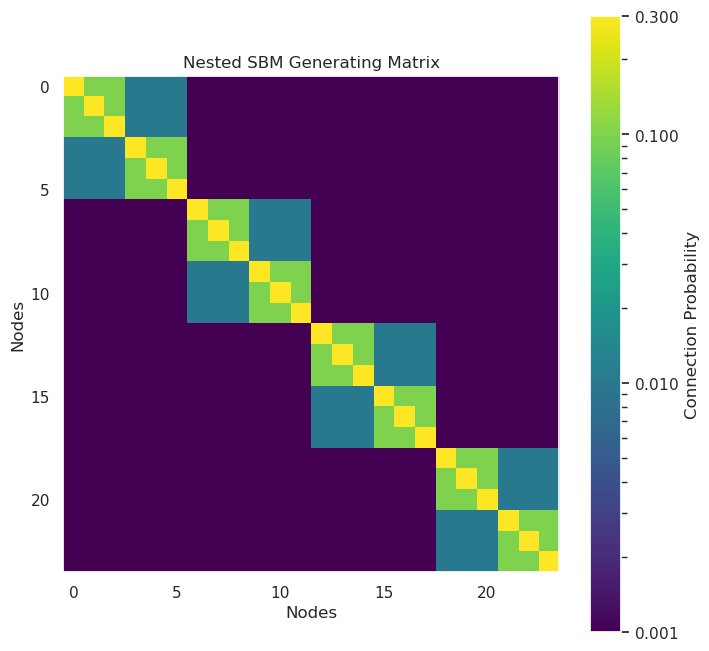

In [15]:
# Parameters
num_levels = 3
num_blocks_per_level = [4, 2, 3]  # Hierarchy: Level 1 = 4 blocks, Level 2 = 2 blocks per block, Level 3 = 2
p_ins = [0.01,0.1,0.3]
p_out = 0.001

# Generate the nested block matrix
prob_matrix = generate_nested_block_matrix(num_levels, num_blocks_per_level, p_ins, p_out)

# Visualize the matrix
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(prob_matrix, cmap='viridis', interpolation='none', norm=LogNorm(vmin=0.001, vmax=0.3), aspect='equal')
t = [0.001, 0.01, 0.1, 0.3]
plt.colorbar(im,ticks=t,format="$%.3f$",label="Connection Probability")
plt.title("Nested SBM Generating Matrix")
plt.xlabel("Nodes")
plt.ylabel("Nodes")
plt.grid(False)
plt.savefig("./figures/nested_sbm_block_structure.svg",
            dpi = 1000) # CONVERT TO PDF BY HAND!
plt.show()
plt.close()

In [7]:
from graph_tool.generation import generate_sbm
from graph_tool.draw import sfdp_layout, graph_draw

def nested_sbm_to_nx(prob_matrix, group_membership, directed=False, visualize=False, image_name="graph.png"):
    """
    Wrapper to generate a nested SBM graph using graph-tool, convert it to NetworkX, and optionally visualize it.

    Args:
        prob_matrix (np.ndarray): Block probability matrix for the SBM.
        group_membership (list or np.ndarray): List indicating group membership for each node.
        directed (bool): Whether the graph should be directed. Default is False.
        visualize (bool): Whether to generate an image of the graph. Default is False.
        image_name (str): Filename for the visualization output. Default is 'graph.png'.

    Returns:
        nx_graph (networkx.Graph or networkx.DiGraph): Converted NetworkX graph.
    """

    # Scale probs matrix to reflect block sizes
    unique_blocks, counts = np.unique(group_membership, return_counts=True)
    block_sizes = {block: count for block, count in zip(unique_blocks, counts)}

    scaled_probs = np.zeros_like(prob_matrix)
    for i in range(prob_matrix.shape[0]):
        for j in range(prob_matrix.shape[1]):
            scaled_probs[i, j] = prob_matrix[i, j] * block_sizes[i] * block_sizes[j]
    
    # Step 1: Generate the graph using graph-tool
    g_gt = generate_sbm(b=group_membership, probs=scaled_probs, directed=directed)
    
    # Step 2: Convert the graph-tool graph to a NetworkX graph
    if directed:
        nx_graph = nx.DiGraph()
    else:
        nx_graph = nx.Graph()
    
    # Add nodes to NetworkX graph
    nx_graph.add_nodes_from(range(g_gt.num_vertices()))
    
    # Add edges with weights (if applicable)
    for e in g_gt.edges():
        source = int(e.source())
        target = int(e.target())
        nx_graph.add_edge(source, target)

    # Step 3: Optionally visualize the graph using graph-tool
    if visualize:
        pos = sfdp_layout(g_gt)  # Layout algorithm
        graph_draw(g_gt, pos, output_size=(500, 500))
        print(f"Graph visualization saved as {image_name}")
    
    return nx_graph

In [8]:
def calculate_block_membership(num_nodes, num_blocks_per_level):
    """
    Calculate group membership for nodes to match specified hierarchical block sizes.

    Args:
        num_nodes (int): Total number of nodes in the network.
        num_blocks_per_level (list of int): Number of blocks at each level.

    Returns:
        list: Group membership list for all nodes.
    """
    # Total number of lowest-level blocks
    total_lowest_blocks = np.prod(num_blocks_per_level)
    
    # Determine base size of each lowest-level block
    base_block_size = num_nodes // total_lowest_blocks
    remainder = num_nodes % total_lowest_blocks  # Handle any leftover nodes

    group_membership = []
    current_index = 0

    # Assign nodes to blocks hierarchically
    def assign_nodes_recursive(level, start_index, block_size):
        nonlocal current_index
        num_blocks = num_blocks_per_level[level]
        sub_block_size = block_size // num_blocks

        for b in range(num_blocks):
            if level == len(num_blocks_per_level) - 1:  # Lowest level
                size = sub_block_size
                # Distribute remainder nodes evenly to the lowest-level blocks
                if current_index < remainder:
                    size += 1
                group_membership.extend([current_index] * size)
                current_index += 1
            else:
                assign_nodes_recursive(level + 1, start_index, sub_block_size)

    # Start recursive assignment
    assign_nodes_recursive(0, 0, num_nodes)
    return group_membership

In [13]:
# Example nested SBM probability matrix (as from earlier)
num_levels = 3
num_blocks_per_level = [4, 2, 3]  # Hierarchy: Level 1 = 4 blocks, Level 2 = 2 blocks per block, Level 3 = 2
p_ins = [0.01,0.1,0.3]
p_out = 0.001

# Generate the probability matrix
prob_matrix = generate_nested_block_matrix(num_levels, num_blocks_per_level, p_ins, p_out)
    
# Example group membership: groups for all nodes
num_nodes = 1000  # Total network size

# Generate group membership
group_membership = calculate_block_membership(num_nodes, num_blocks_per_level)

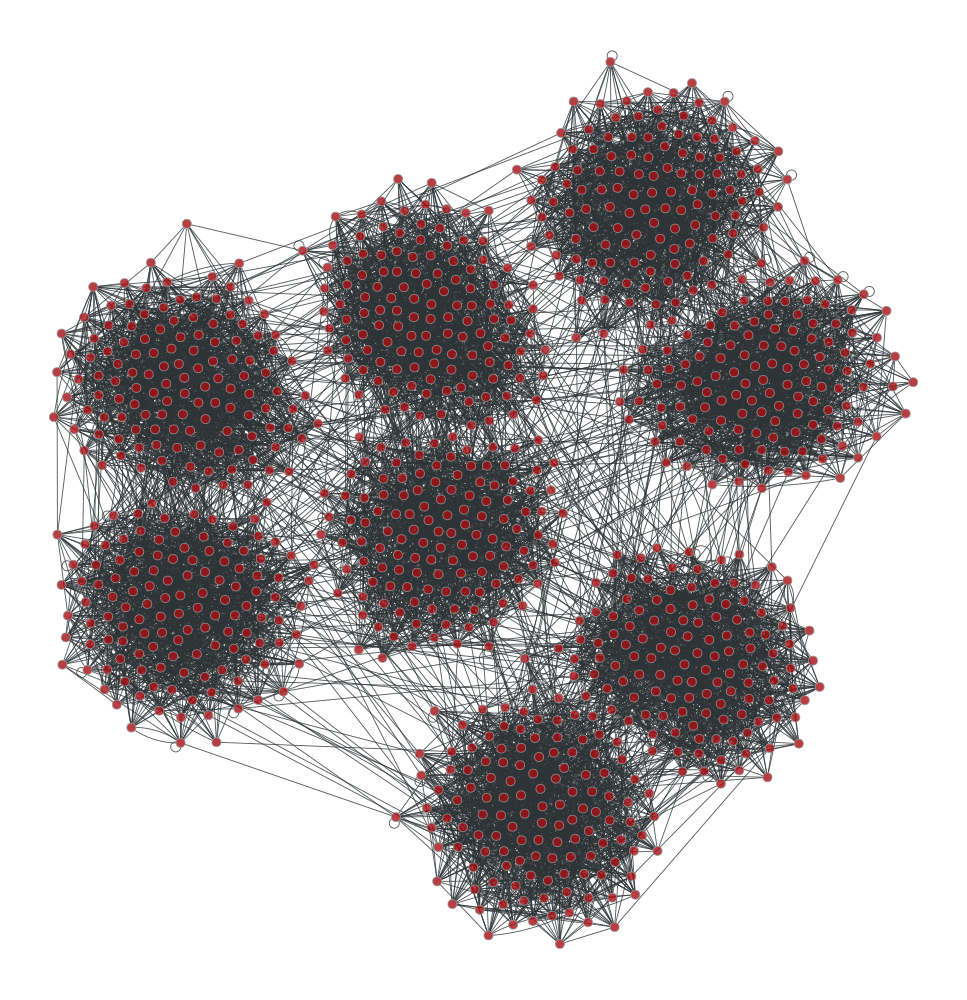

Graph visualization saved as None
Number of nodes in NetworkX graph: 1000
Number of edges in NetworkX graph: 10413


In [14]:
# Call the wrapper function
nx_graph = nested_sbm_to_nx(prob_matrix, group_membership, directed=False, visualize=True, image_name=None)

# Check the result
print("Number of nodes in NetworkX graph:", nx_graph.number_of_nodes())
print("Number of edges in NetworkX graph:", nx_graph.number_of_edges())

In [15]:
G = nx_graph

In [16]:
nx.write_graphml(G, "test_networks/nested_sbm.graphml")

# Init Fitter

In [4]:
filename = './test_networks/nested_sbm.graphml'
G = nx.read_graphml(filename)

In [5]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.447079
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:10.855219


In [6]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 10413},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 181143},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 9265},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 923414},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 1247},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 2843744},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 407591},
 {'name

# Grid Search

In [7]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,11]},
                {'m': 3,  'k': [1,8]},
                {'m': 5,  'k': [1,6]},
                {'m': 7,  'k': [1,5]}],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-02-16 09:16:25,324] A new study created in memory with name: no-name-b74f6ae1-abfc-4416-b50d-576dea9de60a


Grid Search requires 10 trials...


[I 2025-02-16 09:16:32,922] Trial 0 finished with value: 2.1006443129479155 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 2.1006443129479155.
[I 2025-02-16 09:16:47,501] Trial 1 finished with value: 4.002981809004098 and parameters: {'m': 2, 'k': 9}. Best is trial 0 with value: 2.1006443129479155.
[I 2025-02-16 09:16:56,185] Trial 2 finished with value: 2.250497328637151 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 2.1006443129479155.
[I 2025-02-16 09:17:38,149] Trial 3 finished with value: 5.741016212953456 and parameters: {'m': 2, 'k': 10}. Best is trial 0 with value: 2.1006443129479155.
[I 2025-02-16 09:17:45,000] Trial 4 finished with value: 2.821610430542298 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 2.1006443129479155.
[I 2025-02-16 09:17:52,170] Trial 5 finished with value: 2.7710471995602597 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 2.1006443129479155.
[I 2025-02-16 09:18:02,132] Trial 6 finished with value

Grid Search requires 7 trials...


[I 2025-02-16 09:23:24,804] Trial 0 finished with value: 2.619192815848652 and parameters: {'m': 3, 'k': 7}. Best is trial 0 with value: 2.619192815848652.
[I 2025-02-16 09:23:39,366] Trial 1 finished with value: 2.2995835887449427 and parameters: {'m': 3, 'k': 3}. Best is trial 1 with value: 2.2995835887449427.
[I 2025-02-16 09:23:57,510] Trial 2 finished with value: 2.197983159874898 and parameters: {'m': 3, 'k': 2}. Best is trial 2 with value: 2.197983159874898.
[I 2025-02-16 09:24:11,219] Trial 3 finished with value: 2.132479411937742 and parameters: {'m': 3, 'k': 4}. Best is trial 3 with value: 2.132479411937742.
[I 2025-02-16 09:24:29,921] Trial 4 finished with value: 2.8974350565881264 and parameters: {'m': 3, 'k': 1}. Best is trial 3 with value: 2.132479411937742.
[I 2025-02-16 09:25:09,804] Trial 5 finished with value: 2.3103279792443217 and parameters: {'m': 3, 'k': 6}. Best is trial 3 with value: 2.132479411937742.
[I 2025-02-16 09:25:26,085] Trial 6 finished with value: 2.1

Grid Search requires 5 trials...


[I 2025-02-16 09:26:17,722] Trial 0 finished with value: 2.2111138969343407 and parameters: {'m': 5, 'k': 3}. Best is trial 0 with value: 2.2111138969343407.
[I 2025-02-16 09:27:00,488] Trial 1 finished with value: 2.740395830954681 and parameters: {'m': 5, 'k': 1}. Best is trial 0 with value: 2.2111138969343407.
[I 2025-02-16 09:27:53,529] Trial 2 finished with value: 2.1898443330168473 and parameters: {'m': 5, 'k': 2}. Best is trial 2 with value: 2.1898443330168473.
[I 2025-02-16 09:29:22,307] Trial 3 finished with value: 2.161426574661465 and parameters: {'m': 5, 'k': 4}. Best is trial 3 with value: 2.161426574661465.
[I 2025-02-16 10:00:45,350] Trial 4 finished with value: 2.4408490136245393 and parameters: {'m': 5, 'k': 5}. Best is trial 3 with value: 2.161426574661465.
[I 2025-02-16 10:00:45,352] A new study created in memory with name: no-name-ef90f0e5-eeb7-4c98-9da5-c429cdbbed7c


Grid Search requires 4 trials...


[I 2025-02-16 10:04:15,702] Trial 0 finished with value: 2.265590001551605 and parameters: {'m': 7, 'k': 3}. Best is trial 0 with value: 2.265590001551605.
[I 2025-02-16 10:46:43,056] Trial 1 finished with value: 2.625140979393258 and parameters: {'m': 7, 'k': 4}. Best is trial 0 with value: 2.265590001551605.
[I 2025-02-16 10:48:32,281] Trial 2 finished with value: 2.0829380997947258 and parameters: {'m': 7, 'k': 2}. Best is trial 2 with value: 2.0829380997947258.
[I 2025-02-16 10:49:51,803] Trial 3 finished with value: 2.55904673084483 and parameters: {'m': 7, 'k': 1}. Best is trial 2 with value: 2.0829380997947258.


Best parameters:  {'m': 2, 'k': 4}
Best energy:  4.191532783744511
Best KL-divergence:  0.016852569281943473
Best KLD augumented energy: 1.9883585087494962
Best P matrix:
 [[0.61682899 0.07401557]
 [0.07401557 0.76588199]]
Best l vector:
 [0.55748081 0.44251919]


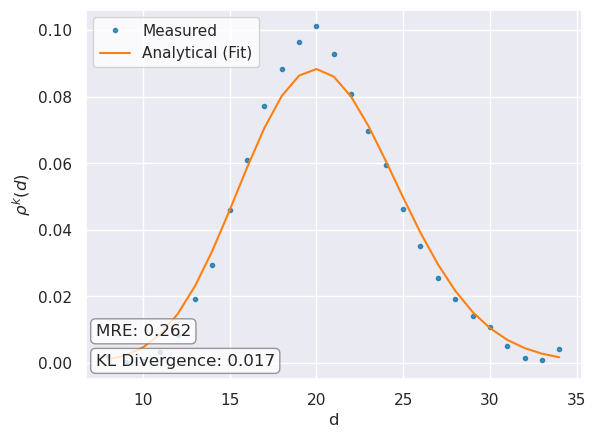

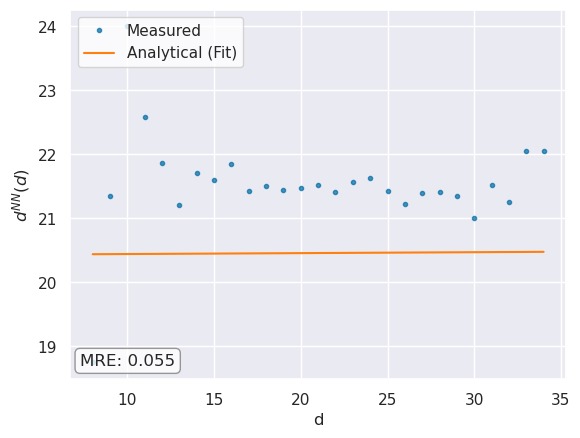

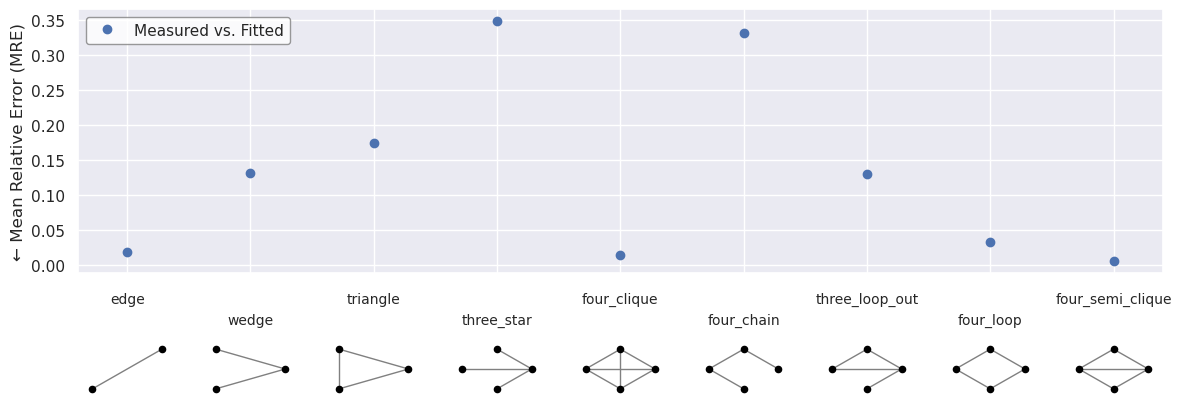

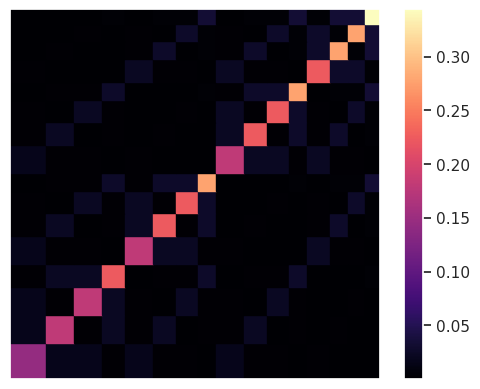

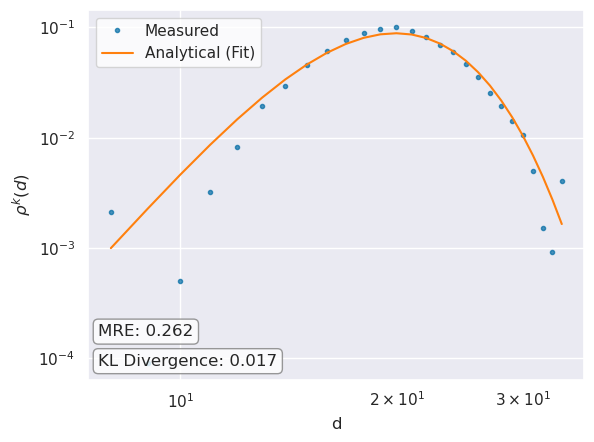

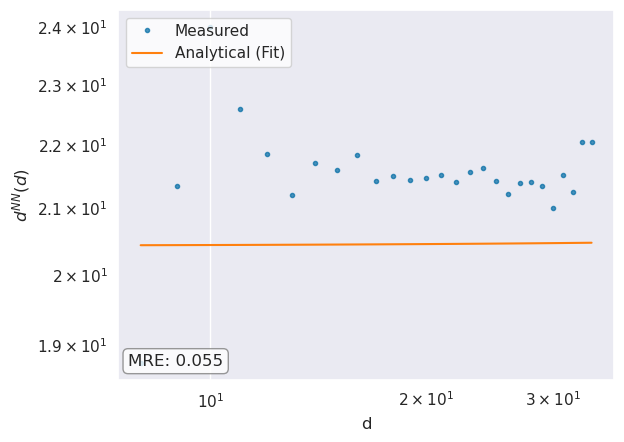

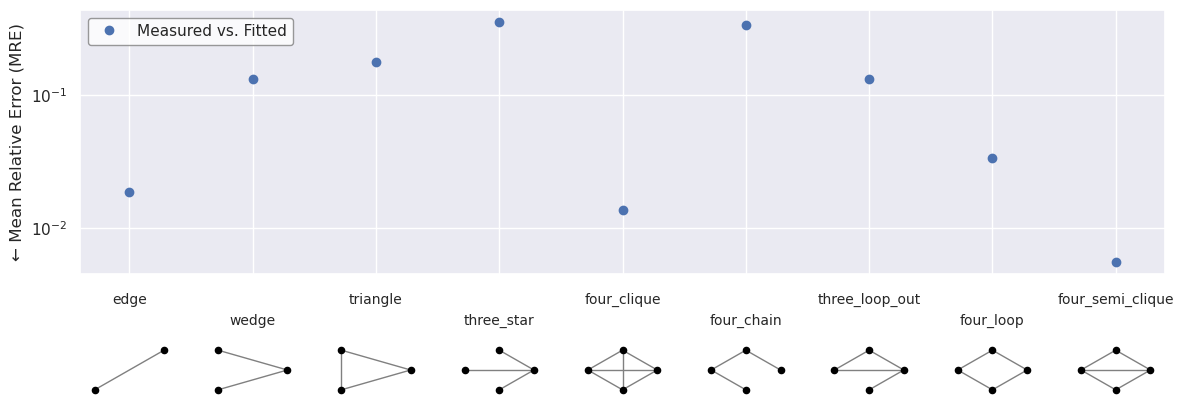

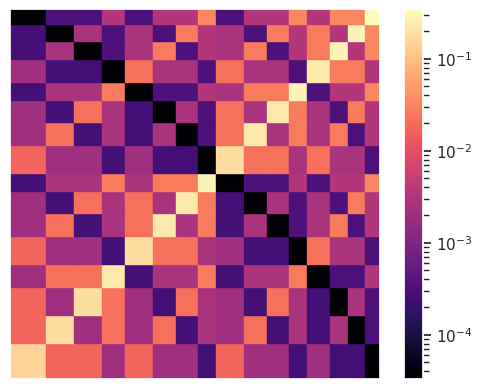

In [8]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/nested_sbm_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/nested_sbm_log_plot.pdf"
)

#### Looking at 'second best' m-k pairs from the grid search

Energy: 3.859422206853663
KL-divergence: 0.04661758658733981
KLD augumented energy: 2.0194166534290554
[[0.55965107 0.07708762 0.75392841]
 [0.07708762 0.84574424 0.53870279]
 [0.75392841 0.53870279 0.47696219]]
[0.60498524 0.38408059 0.01093417]


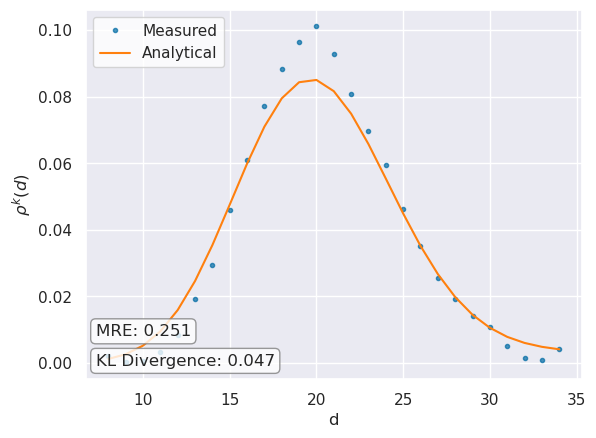

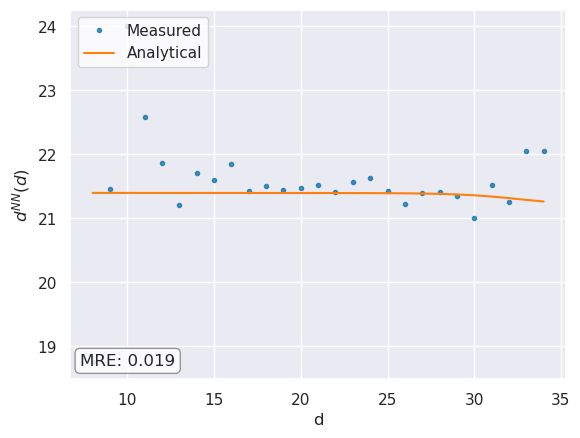

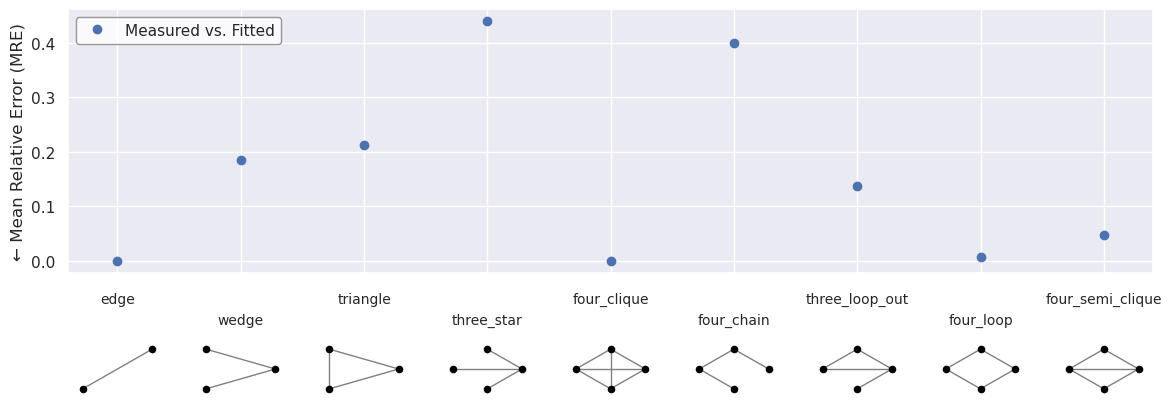

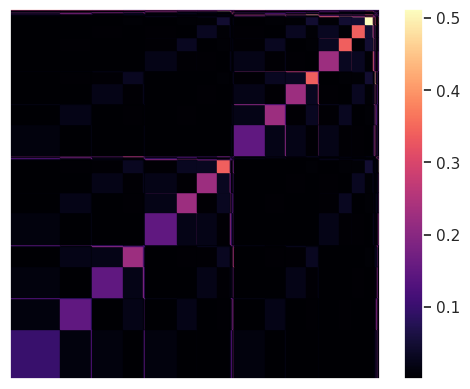

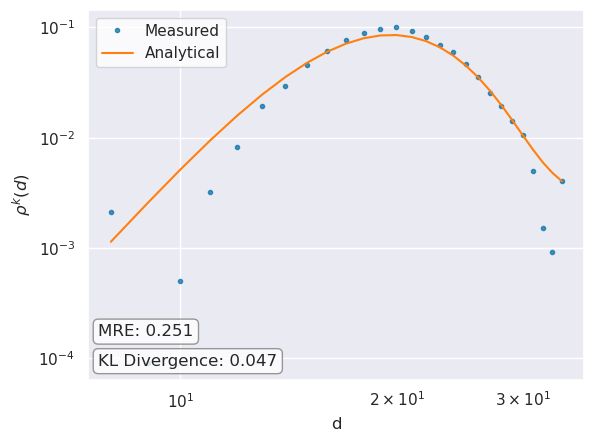

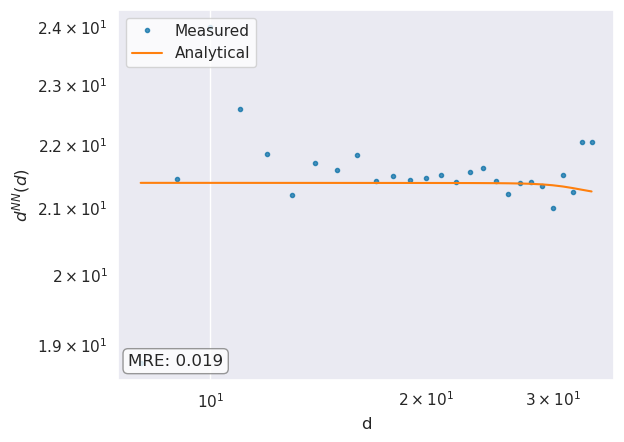

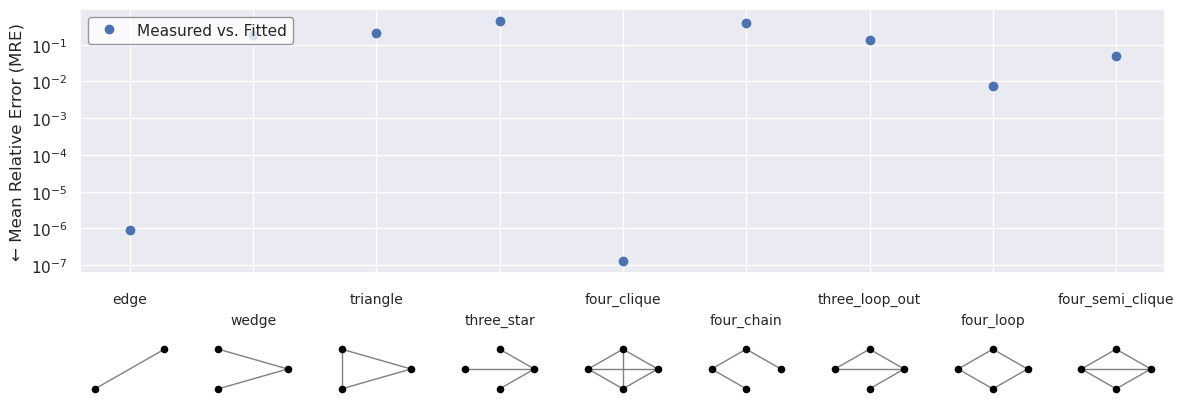

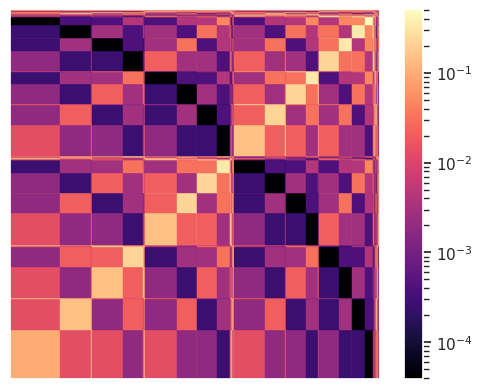

In [22]:
mfnf.find_P_l(m = 3, k = 4, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False
)

Energy: 3.8119463955949624
KL-divergence: 0.0465289291559337
KLD augumented energy: 1.9714770133331874
[[7.02663250e-01 2.16931289e-01 4.59889572e-02 1.00000000e+00
  9.99611422e-01]
 [2.16931289e-01 5.55043922e-01 9.91826501e-01 5.81735116e-03
  1.00000000e+00]
 [4.59889572e-02 9.91826501e-01 7.82524929e-01 1.75004268e-16
  4.27970958e-01]
 [1.00000000e+00 5.81735116e-03 1.75004268e-16 1.17813124e-01
  7.78591678e-08]
 [9.99611422e-01 1.00000000e+00 4.27970958e-01 7.78591678e-08
  1.00528713e-01]]
[0.44812257 0.2821228  0.1967749  0.06433041 0.00864931]


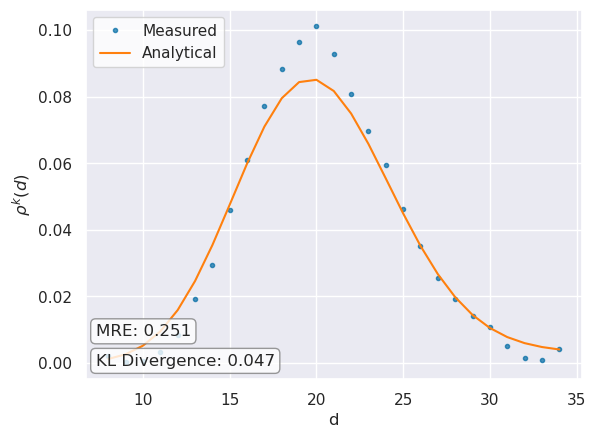

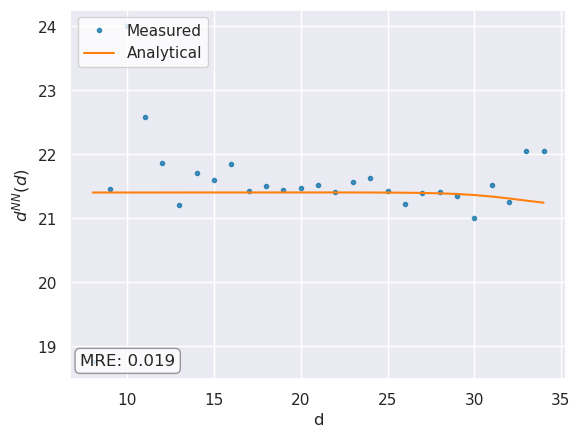

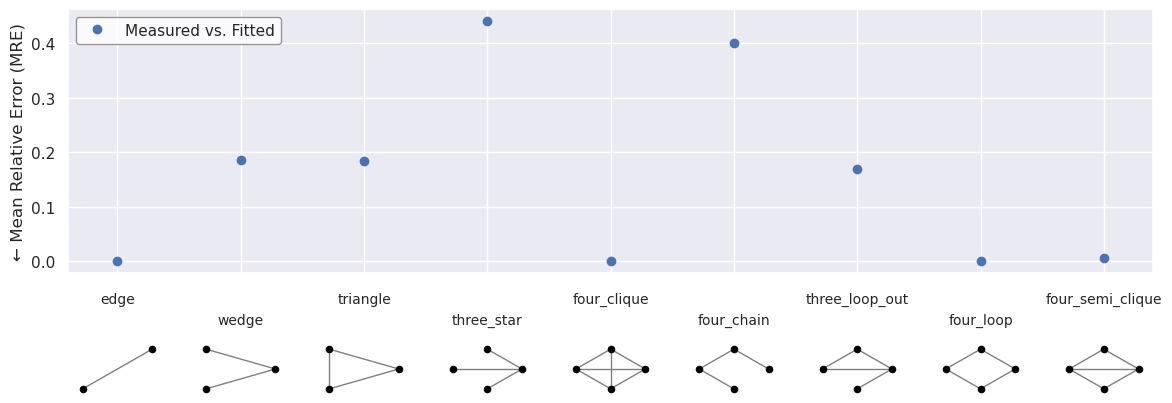

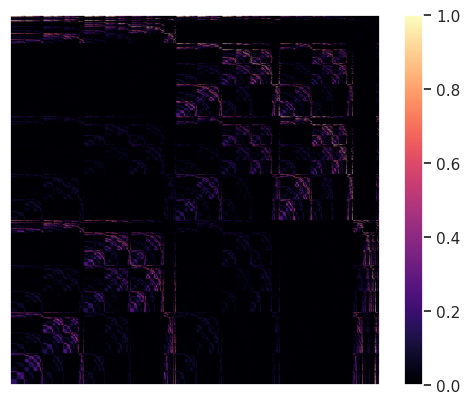

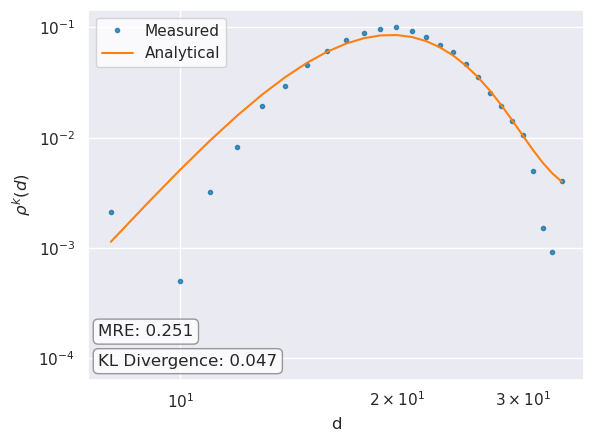

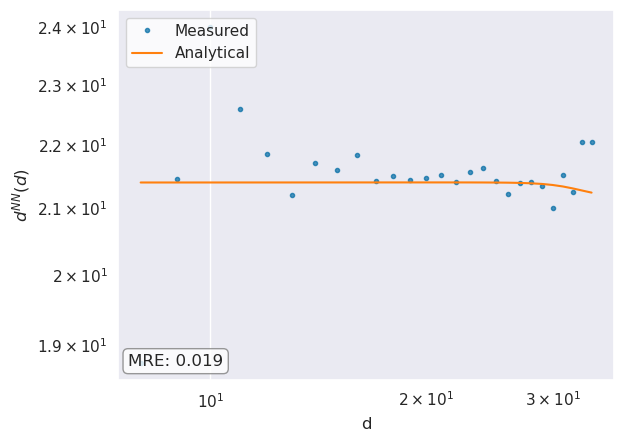

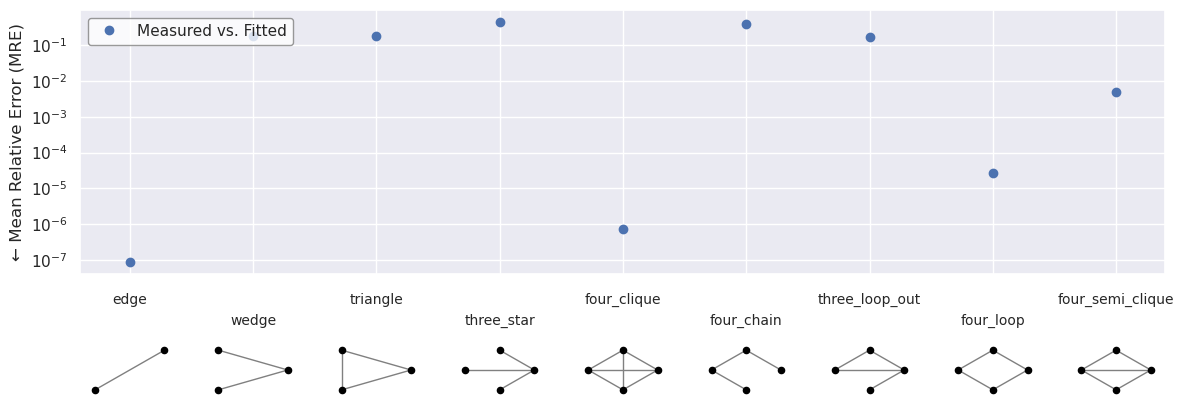

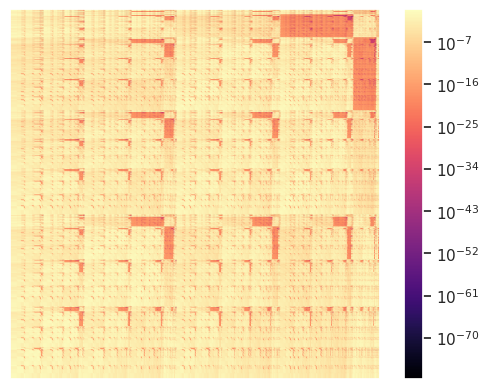

In [23]:
mfnf.find_P_l(m = 5, k = 5, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False
)

Energy: 3.6832375353847833
KL-divergence: 0.0513432523636671
KLD augumented energy: 2.0290161032144063
[[7.69489587e-01 1.38183333e-02 2.22271781e-01 6.69026849e-02
  1.00221617e-01 5.59922014e-01 4.37674994e-02]
 [1.38183333e-02 6.79777656e-01 3.91946552e-01 8.39519286e-01
  8.68813877e-01 9.62733261e-01 5.07253742e-02]
 [2.22271781e-01 3.91946552e-01 8.31620375e-01 2.17284283e-01
  1.86201859e-02 5.75147479e-01 2.99773574e-01]
 [6.69026849e-02 8.39519286e-01 2.17284283e-01 6.19703424e-01
  7.88613397e-01 9.23983340e-01 2.39630774e-17]
 [1.00221617e-01 8.68813877e-01 1.86201859e-02 7.88613397e-01
  1.00000000e+00 2.38029562e-01 9.47144257e-01]
 [5.59922014e-01 9.62733261e-01 5.75147479e-01 9.23983340e-01
  2.38029562e-01 4.74619851e-02 1.34275242e-16]
 [4.37674994e-02 5.07253742e-02 2.99773574e-01 2.39630774e-17
  9.47144257e-01 1.34275242e-16 9.12370283e-01]]
[0.40835193 0.2432854  0.19589322 0.10172039 0.0386401  0.00998787
 0.0021211 ]


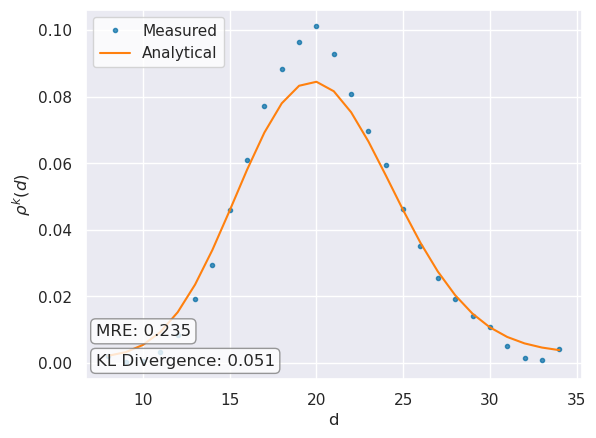

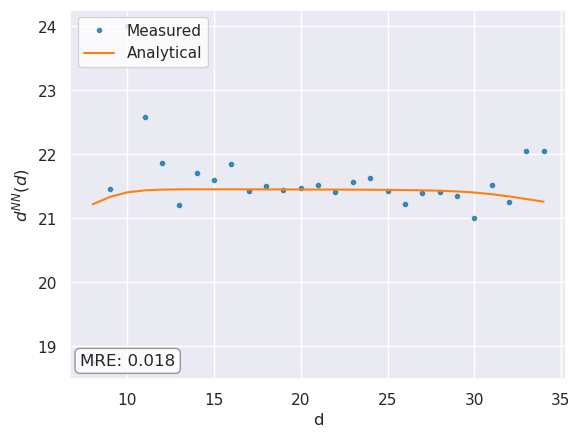

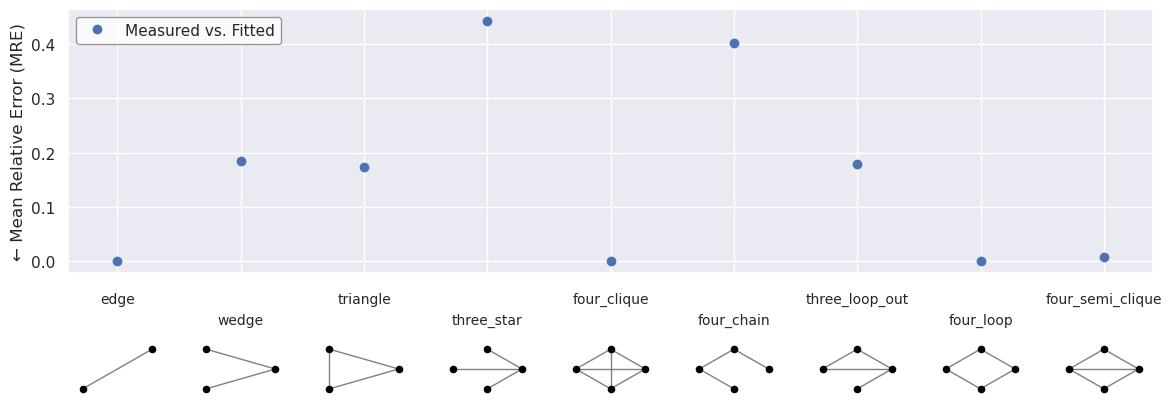

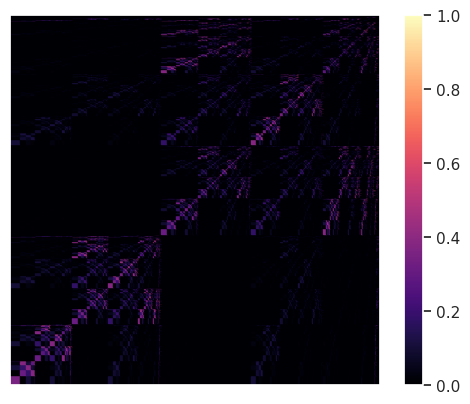

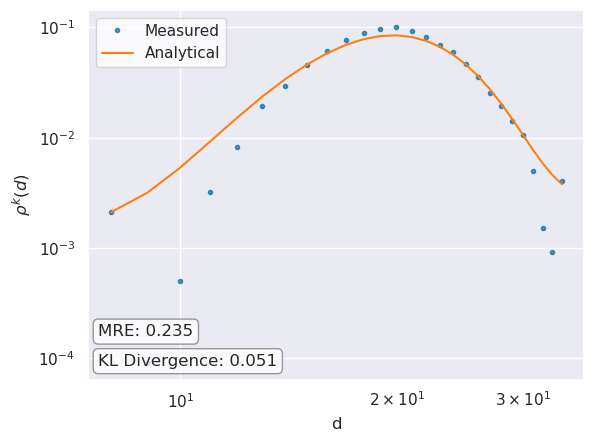

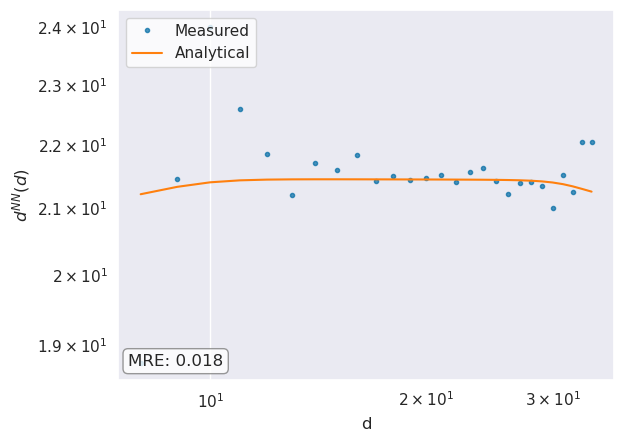

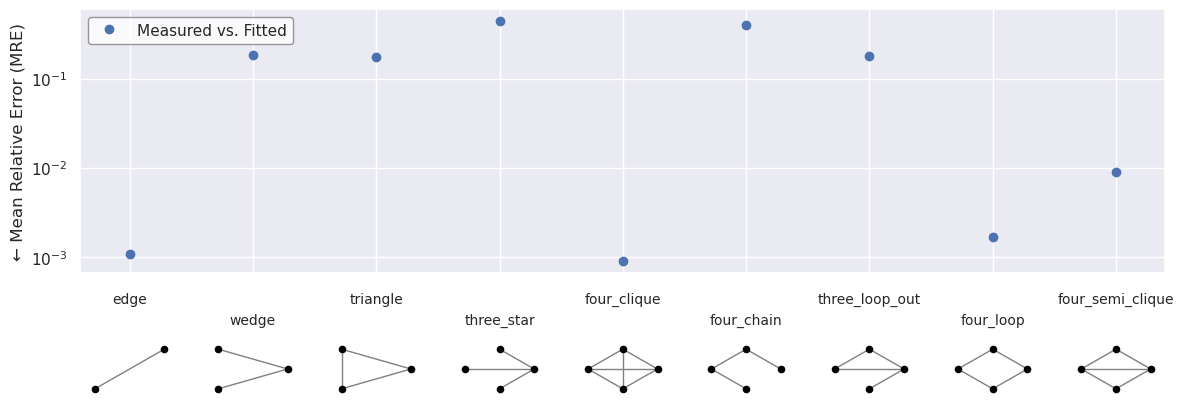

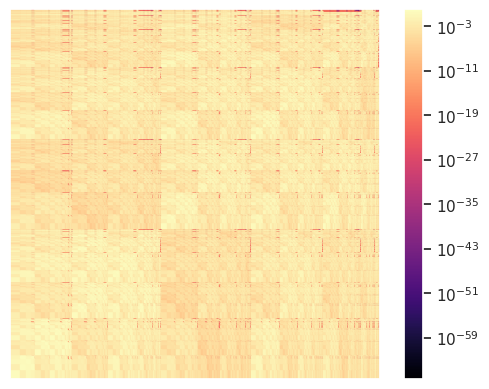

In [24]:
mfnf.find_P_l(m = 7, k = 4, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False
)

# Bootstrapping

In [28]:
mfnf.find_P_l(m = 2, k = 4, one_shot=True)

Energy: 4.159931246336172
KL-divergence: 0.017127583612420123
KLD augumented energy: 1.959318509391881


In [29]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'mean'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [10:34<00:00, 21.14s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:04.728896
Energy = 4.16 (4.16, 4.16)
l = [0.58 (0.58, 0.58), 0.42 (0.42, 0.42)]
P = [
[0.59 (0.59, 0.59), 0.08 (0.08, 0.08)],

[0.08 (0.08, 0.08), 0.80 (0.80, 0.80)]
]


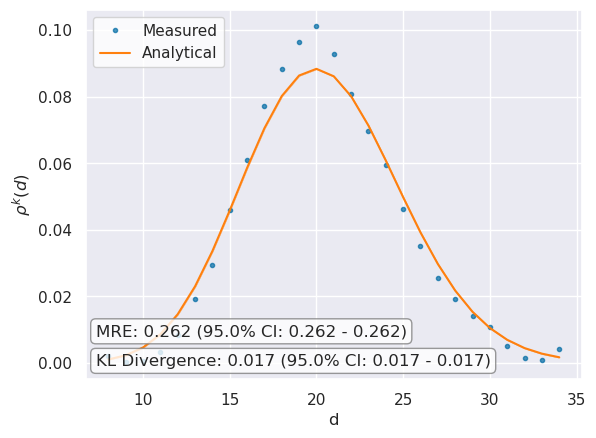

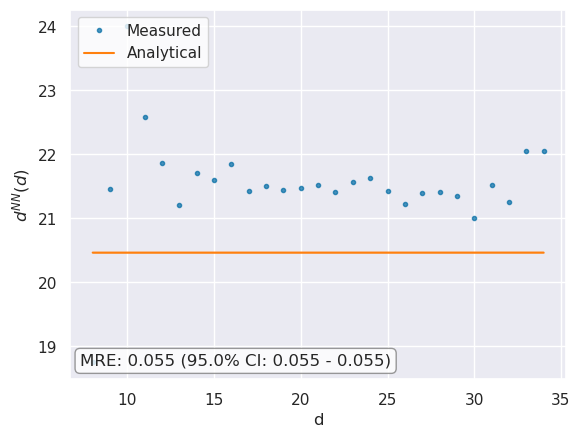

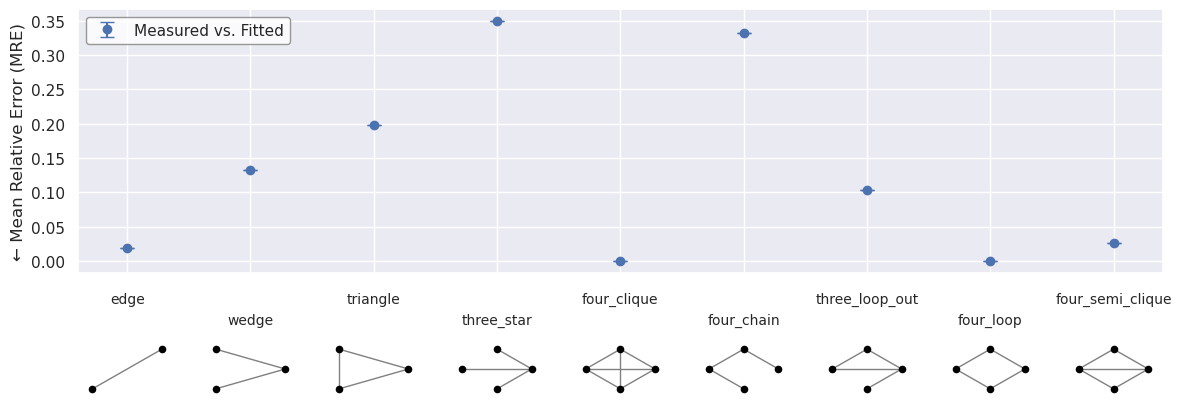

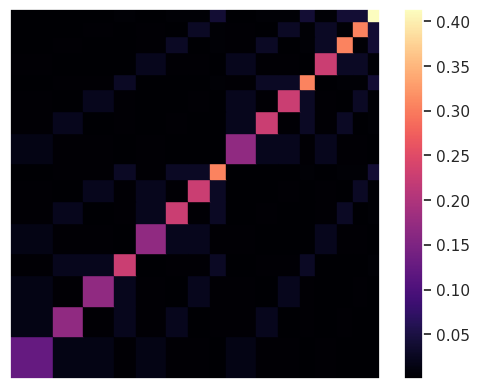

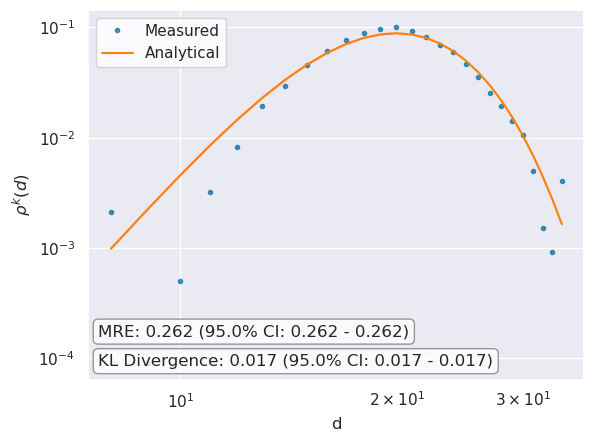

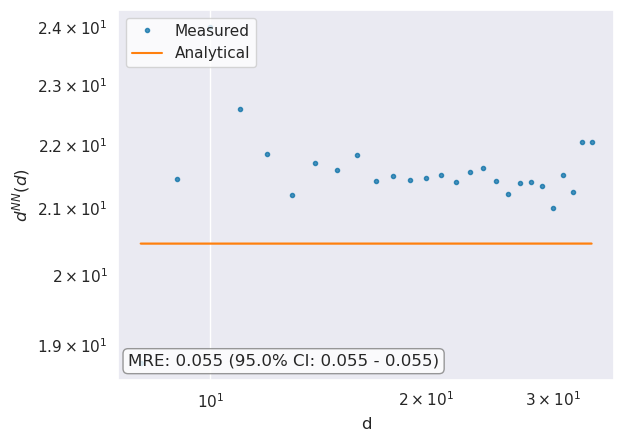

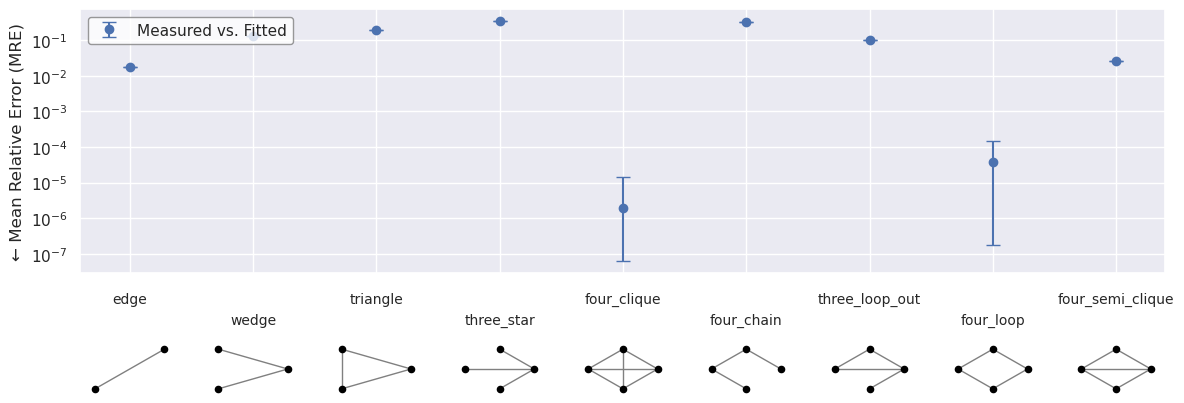

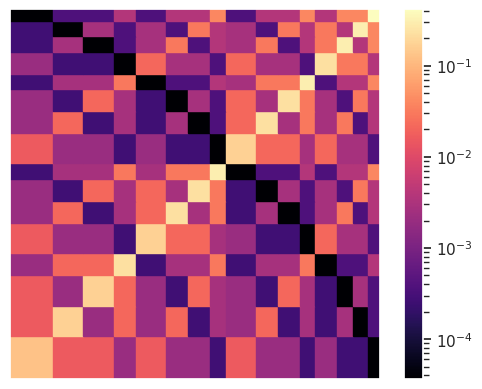

In [30]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_plot_log.pdf"
)

# Generating variant graphs

Initializing...
0.0008552074432373047
Calculating betweenness...
Done.
Calculating node positions...
Done.


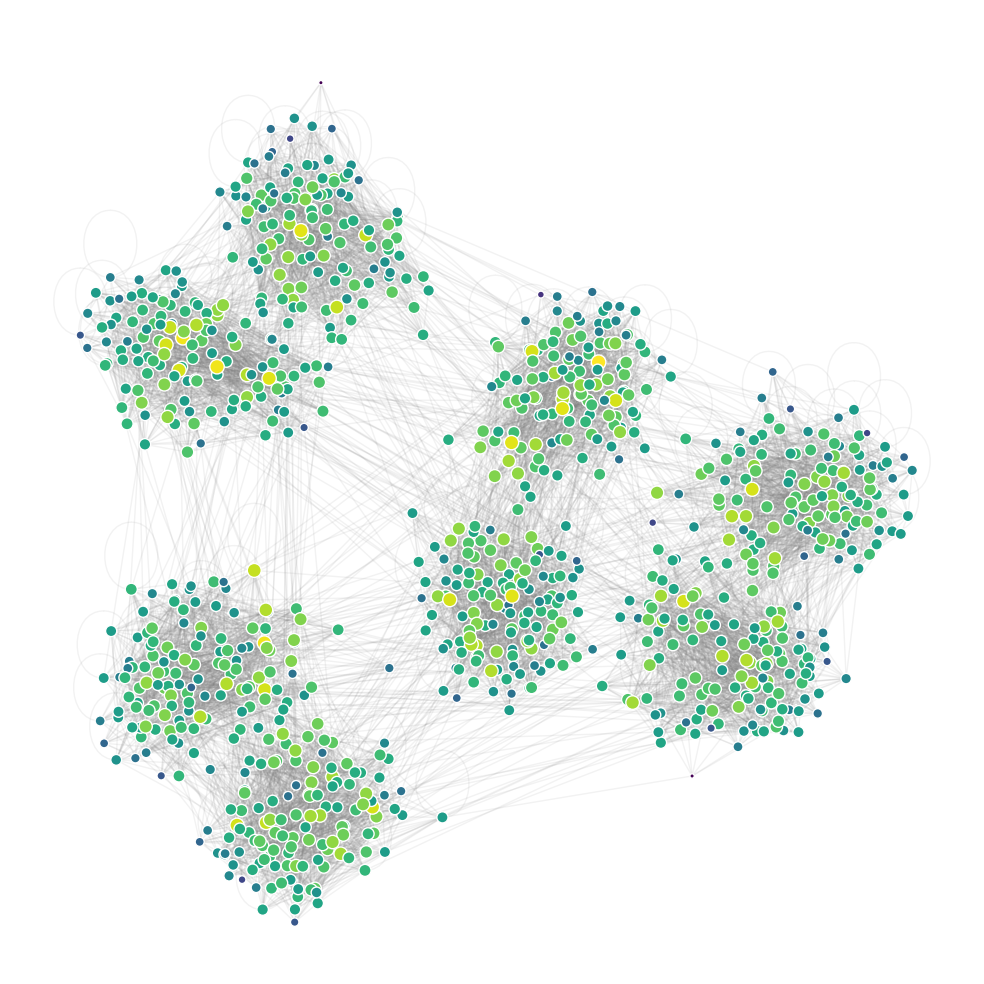

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 140.68it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 285.17it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 322.15it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


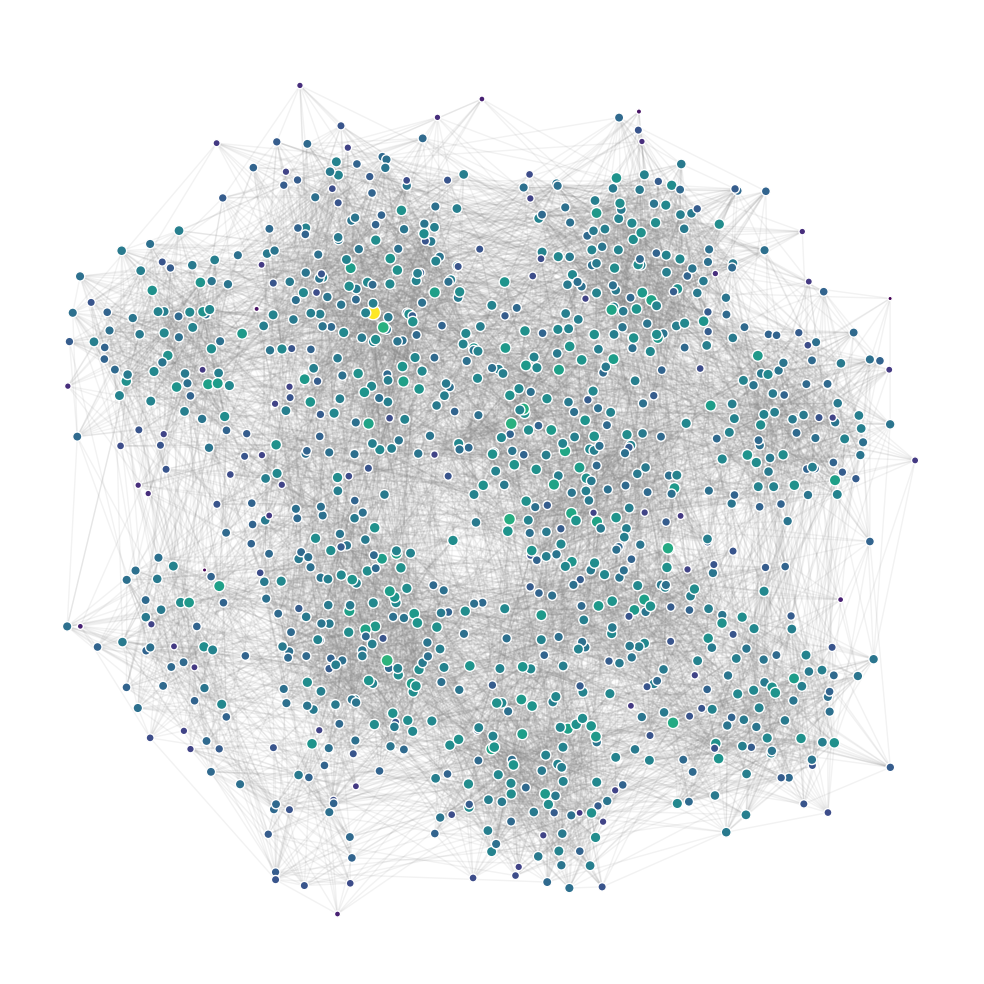

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 153.04it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 305.81it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 272.61it/s]


... (17 outputs left out)

100%|██████████| 32/32 [00:00<00:00, 268.71it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 250.95it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


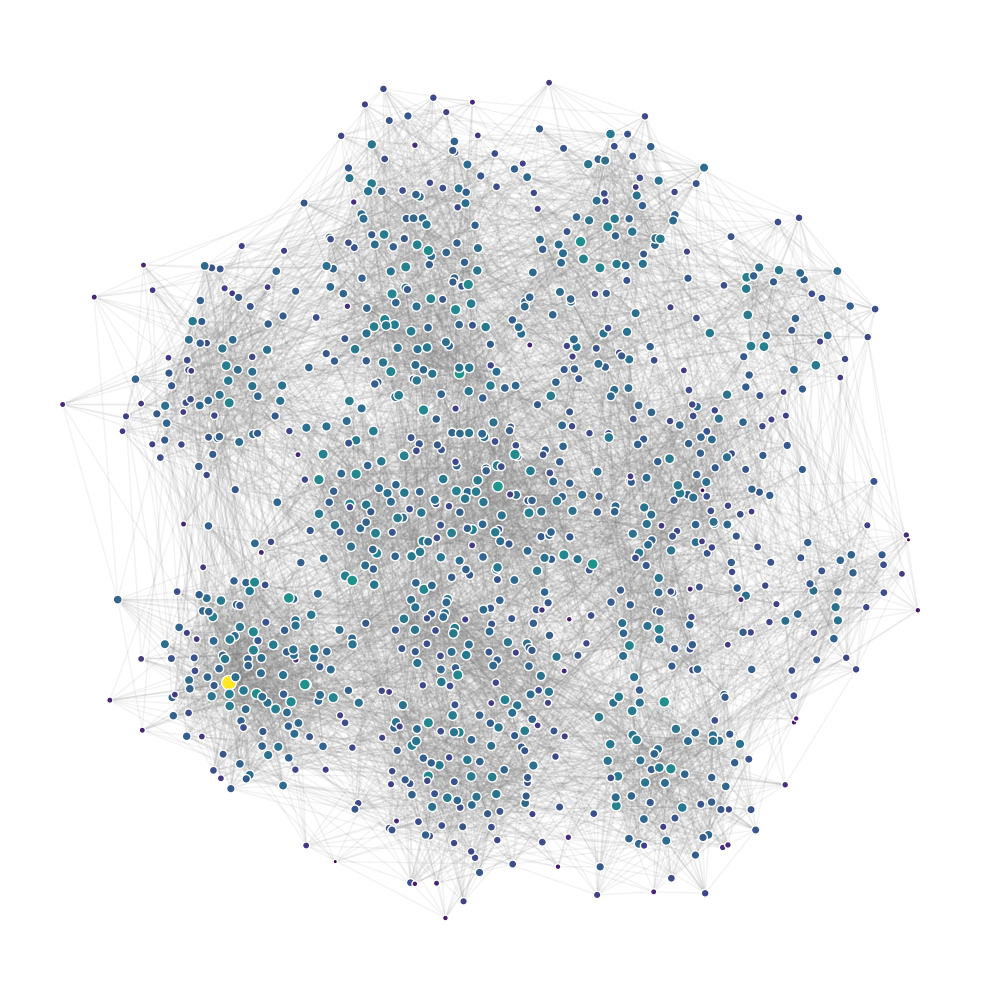

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 165.07it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 245.22it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 280.33it/s]


... (7 outputs left out)

100%|██████████| 32/32 [00:00<00:00, 235.15it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 291.98it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


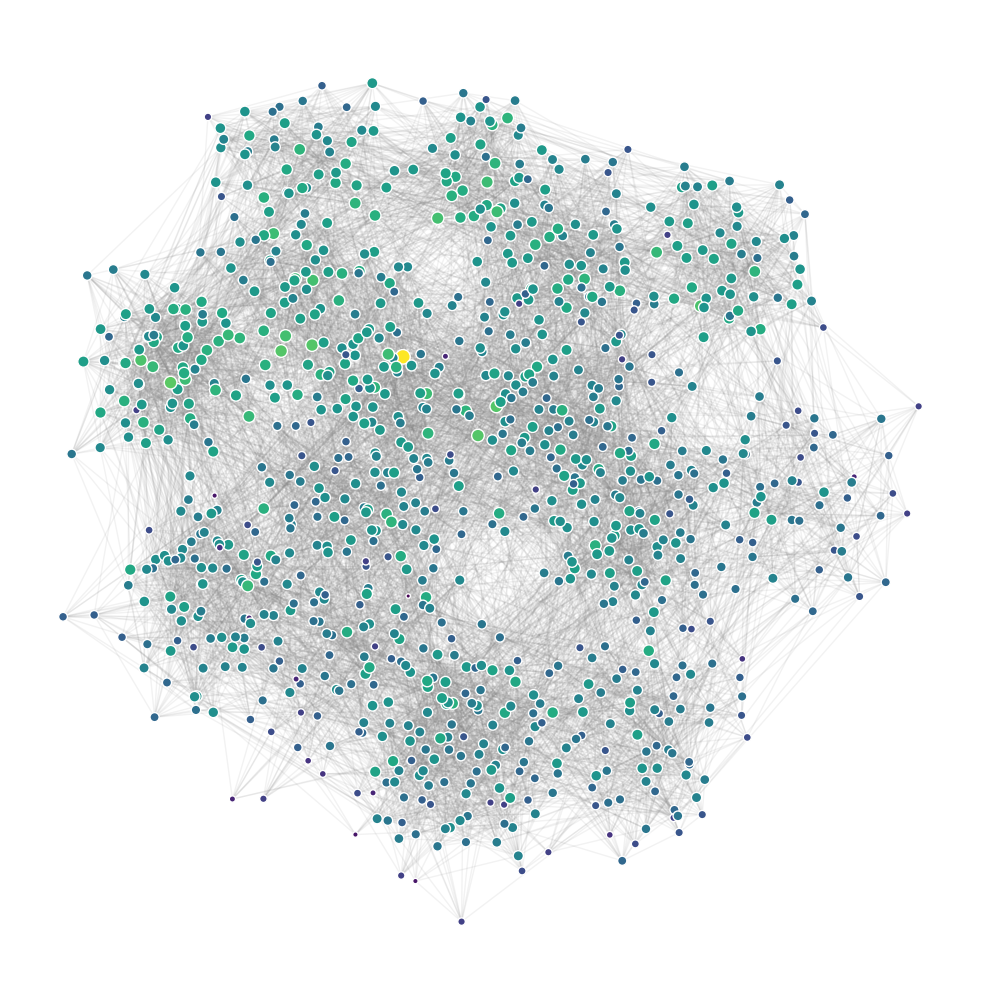

In [31]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.spring_layout,
        'figsize': (10,10),
        'filename':  "figures/nested_sbm_variants.pdf"
    },
    filename = "variant_networks/nested_sbm_variants.graphml"
)